# Thread Count 01: data profile and market share

US imports of apparel (HS chapters 61 knitted and 62 woven) from Bangladesh and seven competitors, January 2017 to September 2026, from the US Census Bureau international trade API.

Questions in this notebook:

1. Is the data complete and does it add up?
2. How has each country's share of US apparel imports moved?
3. China lost about 9 share points between 2024 and 2026. Which products did it lose, and who picked them up?
4. How do Bangladesh's tariff steps line up with the dated tariff actions?

Comparisons use January to September of each year, because 2026 data stops in September.

In [1]:
import duckdb, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "03_analysis" else Path.cwd()
con = duckdb.connect(str(ROOT / "01_data/processed/thread_count.duckdb"), read_only=True)
events = pd.read_csv(ROOT / "01_data/reference/tariff_events.csv", parse_dates=["date"])

GREEN, OCHRE, TOMATO, SLATE, LIGHT = "#1D4A35", "#B87318", "#F2462E", "#7D8D99", "#3B8A60"
COLORS = {"bangladesh": TOMATO, "china": SLATE, "vietnam": GREEN, "india": OCHRE,
          "cambodia": LIGHT, "indonesia": "#A88B5C", "pakistan": "#9AA5A0", "sri_lanka": "#C9B89A"}
plt.rcParams.update({"figure.facecolor": "#F7F1E6", "axes.facecolor": "#F7F1E6", "axes.edgecolor": "#DCCFB6",
                     "axes.grid": True, "grid.color": "#E6DCC8", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10, "text.color": "#16382A",
                     "axes.labelcolor": "#4F5E52", "xtick.color": "#4F5E52", "ytick.color": "#4F5E52"})
pd.set_option("display.float_format", "{:,.2f}".format)
APPAREL = "('61','62')"
YEARS = (2024, 2025, 2026)

## 1. Data profile

In [2]:
con.sql("""
select country, count(*) as rows, count(distinct hs6) as hs6_codes,
       min(month) as first_month, max(month) as last_month, count(distinct month) as months,
       round(sum(gen_value)/1e9, 1) as gen_value_bn
from silver.imports group by country order by gen_value_bn desc
""").df()

,country,rows,hs6_codes,first_month,last_month,months,gen_value_bn
0,china,33789,303,2017-01-01,2026-09-01,117,394.30
1,vietnam,31089,300,2017-01-01,2026-09-01,117,221.80
2,india,31640,303,2017-01-01,2026-09-01,117,73.50
3,bangladesh,26465,293,2017-01-01,2026-09-01,117,69.50
4,indonesia,27175,297,2017-01-01,2026-09-01,117,65.20
5,cambodia,24107,293,2017-01-01,2026-09-01,117,43.00
6,pakistan,27361,299,2017-01-01,2026-09-01,117,33.40
7,sri_lanka,20610,276,2017-01-01,2026-09-01,117,17.80


In [3]:
# Gaps: every country x chapter should have all months from Jan 2017 to Sep 2026
gaps = con.sql("""
with expected as (select count(distinct month) n from silver.world)
select country, chapter, count(distinct month) as months, (select n from expected) as expected
from silver.imports group by all having count(distinct month) < (select n from expected)
""").df()
gaps

,country,chapter,months,expected
0,sri_lanka,64,116,117


Only Sri Lanka footwear (chapter 64) misses one month, which is outside the apparel scope here.

In [4]:
# Checks: no negative values, duty never above value, and the eight countries never exceed the world total
checks = con.sql(f"""
select
  (select count(*) from silver.imports where gen_value < 0 or con_value < 0 or duty < 0) as negative_rows,
  (select count(*) from silver.imports where duty > con_value and con_value > 0) as duty_above_value,
  (select count(*) from (
      select s.hs6, s.month, sum(s.gen_value) v, any_value(w.gen_value) wv
      from silver.imports s join silver.world w using (hs6, month)
      group by all having sum(s.gen_value) > any_value(w.gen_value) * 1.001)) as hs6_months_over_world
""").df()
checks

,negative_rows,duty_above_value,hs6_months_over_world
0,0,14,0


All 14 rows where duty is above value are China in April and May 2025, when China's extra tariff reached 145%. They are real, not errors.

In [5]:
# General imports vs imports for consumption: how far apart are the two value measures?
con.sql(f"""
select year(month) as year, round(sum(gen_value)/1e9,2) as general_bn, round(sum(con_value)/1e9,2) as consumption_bn,
       round(100*(sum(con_value)/sum(gen_value)-1),2) as pct_gap
from silver.imports where chapter in {APPAREL} and country='bangladesh' group by 1 order by 1
""").df()

,year,general_bn,consumption_bn,pct_gap
0,2017,4.89,4.86,-0.64
1,2018,5.24,5.30,1.26
2,2019,5.72,5.85,2.16
3,2020,5.09,5.16,1.41
4,2021,6.88,6.92,0.70
5,2022,9.29,9.20,-1.02
6,2023,6.93,7.10,2.45
7,2024,7.05,7.12,1.04
8,2025,7.88,8.03,1.93
9,2026,5.90,5.99,1.41


Shares use **general imports** (goods arriving in the US). Tariff rates use **imports for consumption** and calculated duty, the same basis Census uses for duty. The two differ by goods held in bonded warehouses; for Bangladesh apparel the gap is small, as the table shows.

## 2. Share of US apparel imports

In [6]:
share_year = con.sql(f"""
with c as (select country, year(month) y, sum(gen_value) v from silver.imports
           where chapter in {APPAREL} and month(month) <= 9 group by all),
     w as (select year(month) y, sum(gen_value) wv from silver.world
           where chapter in {APPAREL} and month(month) <= 9 group by all)
select country, y as year, v/1e9 as value_bn, 100*v/wv as share_pct from c join w using (y)
""").df()
world_year = con.sql(f"""select year(month) as yr, sum(gen_value)/1e9 world_bn from silver.world
  where chapter in {APPAREL} and month(month)<=9 group by 1 order by 1""").df().rename(columns={"yr": "year"})
tbl = share_year.pivot(index="country", columns="year", values="share_pct").sort_values(2026, ascending=False)
tbl["change_24_26"] = tbl[2026] - tbl[2024]
tbl[[2017, 2019, 2022, 2024, 2025, 2026, "change_24_26"]]

year,2017,2019,2022,2024,2025,2026,change_24_26
country,,,,,,,
vietnam,14.11,15.65,18.26,18.40,20.61,21.97,3.57
china,33.71,31.22,22.75,21.82,15.05,12.55,-9.27
bangladesh,6.22,6.72,9.13,8.67,10.12,10.30,1.63
cambodia,2.66,3.14,4.53,4.70,5.95,6.74,2.03
indonesia,5.75,5.21,5.64,5.31,5.92,6.43,1.12
india,4.78,4.95,5.90,6.09,6.77,5.40,-0.69
pakistan,1.61,1.71,2.78,2.67,2.99,3.07,0.40
sri_lanka,2.39,2.10,2.10,2.08,2.23,2.28,0.20


In [7]:
world_year.set_index("year").T

year,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
world_bn,61.13,62.78,65.64,50.74,59.60,79.08,61.22,60.05,60.95,57.33


In [8]:
val = share_year.pivot(index="country", columns="year", values="value_bn")
val[[2024, 2025, 2026]].assign(change_bn=val[2026]-val[2024]).sort_values(2026, ascending=False)

year,2024,2025,2026,change_bn
country,,,,
vietnam,11.05,12.56,12.59,1.54
china,13.10,9.17,7.19,-5.91
bangladesh,5.20,6.17,5.90,0.70
cambodia,2.82,3.62,3.86,1.04
indonesia,3.19,3.61,3.68,0.50
india,3.66,4.13,3.09,-0.56
pakistan,1.60,1.82,1.76,0.16
sri_lanka,1.25,1.36,1.31,0.06


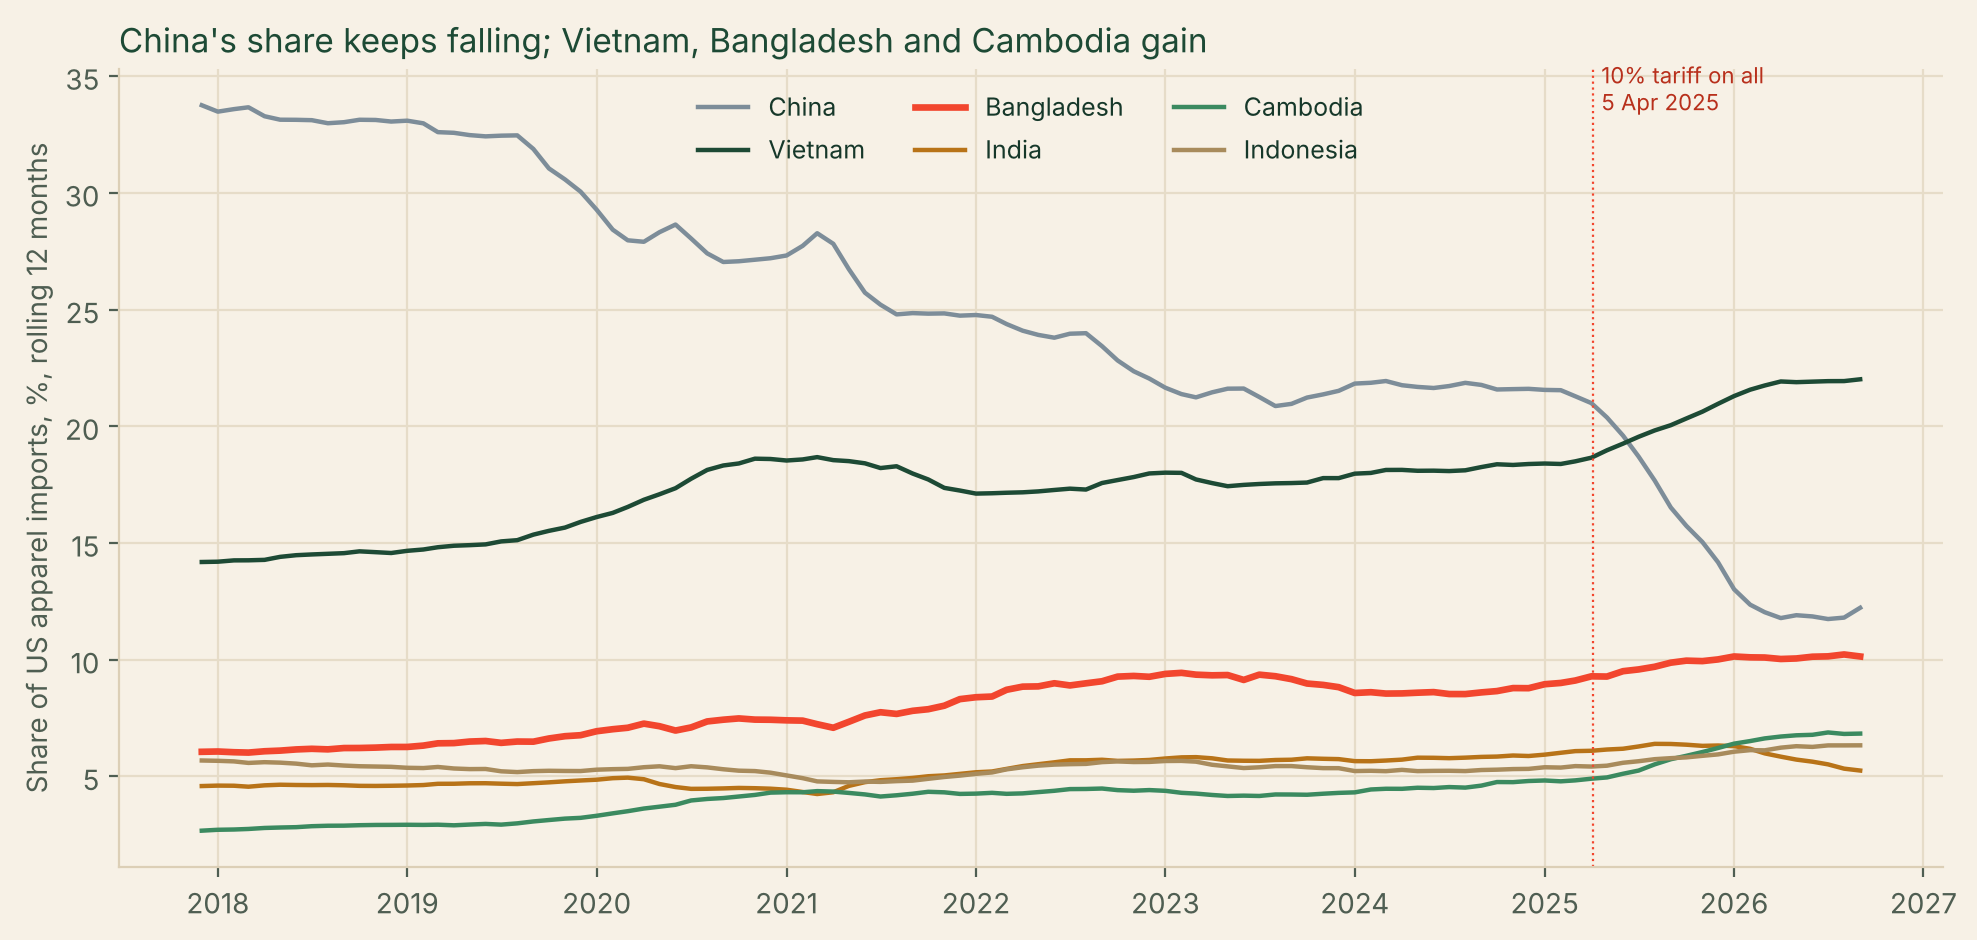

In [9]:
# Rolling 12 month share, monthly
m = con.sql(f"""
with c as (select country, month, sum(gen_value) v from silver.imports where chapter in {APPAREL} group by all),
     w as (select month, sum(gen_value) wv from silver.world where chapter in {APPAREL} group by all)
select country, month, v, wv from c join w using (month) order by country, month
""").df()
m["month"] = pd.to_datetime(m["month"])
m = m.sort_values(["country", "month"])
m["v12"] = m.groupby("country")["v"].transform(lambda s: s.rolling(12).sum())
m["wv12"] = m.groupby("country")["wv"].transform(lambda s: s.rolling(12).sum())
m["share12"] = 100 * m["v12"] / m["wv12"]

fig, ax = plt.subplots(figsize=(10, 4.8))
for ctry in ["china", "vietnam", "bangladesh", "india", "cambodia", "indonesia"]:
    d = m[m.country == ctry]
    ax.plot(d.month, d.share12, color=COLORS[ctry], lw=2.4 if ctry == "bangladesh" else 1.6, label=ctry.title())
ax.axvline(pd.Timestamp("2025-04-05"), color=TOMATO, lw=0.8, ls=":")
ax.text(pd.Timestamp("2025-04-20"), ax.get_ylim()[1]*0.95, "10% tariff on all\n5 Apr 2025", fontsize=8, color="#B8301C")
ax.set_ylabel("Share of US apparel imports, %, rolling 12 months")
ax.set_title("China's share keeps falling; Vietnam, Bangladesh and Cambodia gain", loc="left", fontsize=12, color=GREEN)
ax.legend(ncol=3, frameon=False, fontsize=9); ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y")); plt.tight_layout(); plt.show()

## 3. Where China's lost share went

A country's share of all apparel imports is the sum, over every HS6 product, of its imports of that product divided by total apparel imports. So the change in share between January to September 2024 and 2026 splits exactly into one contribution per product. Positive means the product added share points to that country.

In [10]:
hs = con.sql(f"""
with c as (select country, hs6, any_value(description) descr, year(month) y, sum(gen_value) v
           from silver.imports where chapter in {APPAREL} and month(month)<=9 and year(month) in (2024, 2026)
           group by country, hs6, y),
     w as (select year(month) y, sum(gen_value) wv from silver.world
           where chapter in {APPAREL} and month(month)<=9 and year(month) in (2024, 2026) group by 1)
select country, hs6, descr, y, v, 100*v/wv as pts from c join w using (y)
""").df()
contrib = hs.pivot_table(index=["country", "hs6"], columns="y", values="pts", aggfunc="sum").fillna(0)
contrib["pts_change"] = contrib[2026] - contrib[2024]
contrib = contrib.reset_index()
desc = hs.groupby("hs6")["descr"].first()

# Check: product contributions add up to the headline share change
check = contrib.groupby("country")["pts_change"].sum().rename("sum_of_products").to_frame()
check["headline"] = tbl["change_24_26"]
assert (check["sum_of_products"] - check["headline"]).abs().max() < 1e-6
check.sort_values("headline")

,sum_of_products,headline
country,,
china,-9.27,-9.27
india,-0.69,-0.69
sri_lanka,0.20,0.20
pakistan,0.40,0.40
indonesia,1.12,1.12
bangladesh,1.63,1.63
cambodia,2.03,2.03
vietnam,3.57,3.57


In [11]:
china = contrib[contrib.country == "china"].nsmallest(15, "pts_change")
top = china.hs6.tolist()
gain = contrib[contrib.hs6.isin(top)].pivot(index="hs6", columns="country", values="pts_change").loc[top]
gain.insert(0, "product", desc.loc[top].str.slice(0, 45).values)
cols = ["product", "china", "vietnam", "bangladesh", "cambodia", "indonesia", "india", "pakistan", "sri_lanka"]
gain[cols]

country,product,china,vietnam,bangladesh,cambodia,indonesia,india,pakistan,sri_lanka
hs6,,,,,,,,,
611596,STOCKNG/SOCKS/OTH HOSIERY ETC. OF SYN FIBERS,-0.53,0.09,0.00,0.12,0.00,-0.03,0.02,0.00
611020,"SWEATERS, PULLOVERS ETC, KNIT ETC, COTTON",-0.49,0.26,0.22,0.23,0.15,-0.09,0.06,-0.01
611030,"SWEATERS, PULLOVERS ETC, KNIT ETC, MANMADE FI",-0.49,0.25,0.06,0.19,0.08,-0.00,0.00,0.02
620462,"WOMEN'S OR GIRLS' TROUSERS ETC NOT KNIT, COTT",-0.46,0.04,0.42,0.06,-0.01,0.03,0.02,-0.02
621210,"BRASSIERES, KNIT OR CROCHETED OR NOT",-0.44,0.14,0.02,0.03,0.04,-0.01,-0.00,0.04
620343,"MEN'S OR BOYS' TROUSERS ETC, NOT KNIT, SYNTH",-0.32,-0.01,0.01,0.03,-0.00,0.00,0.00,0.01
620240,WOMEN'S OR GIRLS' OVERCOAT ETC OF MAN-MADE FI,-0.28,0.11,0.04,0.03,0.04,0.00,0.00,0.00
610832,"W/G NIGHTDRESSES & PAJAMAS MANMADE FIBERS, KN",-0.28,0.06,0.02,0.12,0.08,-0.00,0.00,-0.01
620140,MEN'S OR BOYS' OVERCOAT ETC OF MAN-MADE FIBER,-0.24,0.14,0.06,0.03,0.03,-0.00,0.00,0.00


Countries outside the eight, and changes in each product's weight in total imports, take up the rest, so a row does not sum to zero. Totals over China's 15 biggest losses:

In [12]:
tot = gain.drop(columns=["product"]).sum().sort_values()
print(f"China lost {-tot['china']:.2f} share points in these 15 products "
      f"(of {-tbl.loc['china','change_24_26']:.2f} in total).")
tot.to_frame("share_points_in_top15")

China lost 4.76 share points in these 15 products (of 9.27 in total).


,share_points_in_top15
country,
china,-4.76
india,-0.11
sri_lanka,0.07
pakistan,0.19
indonesia,0.45
bangladesh,1.02
cambodia,1.06
vietnam,1.35


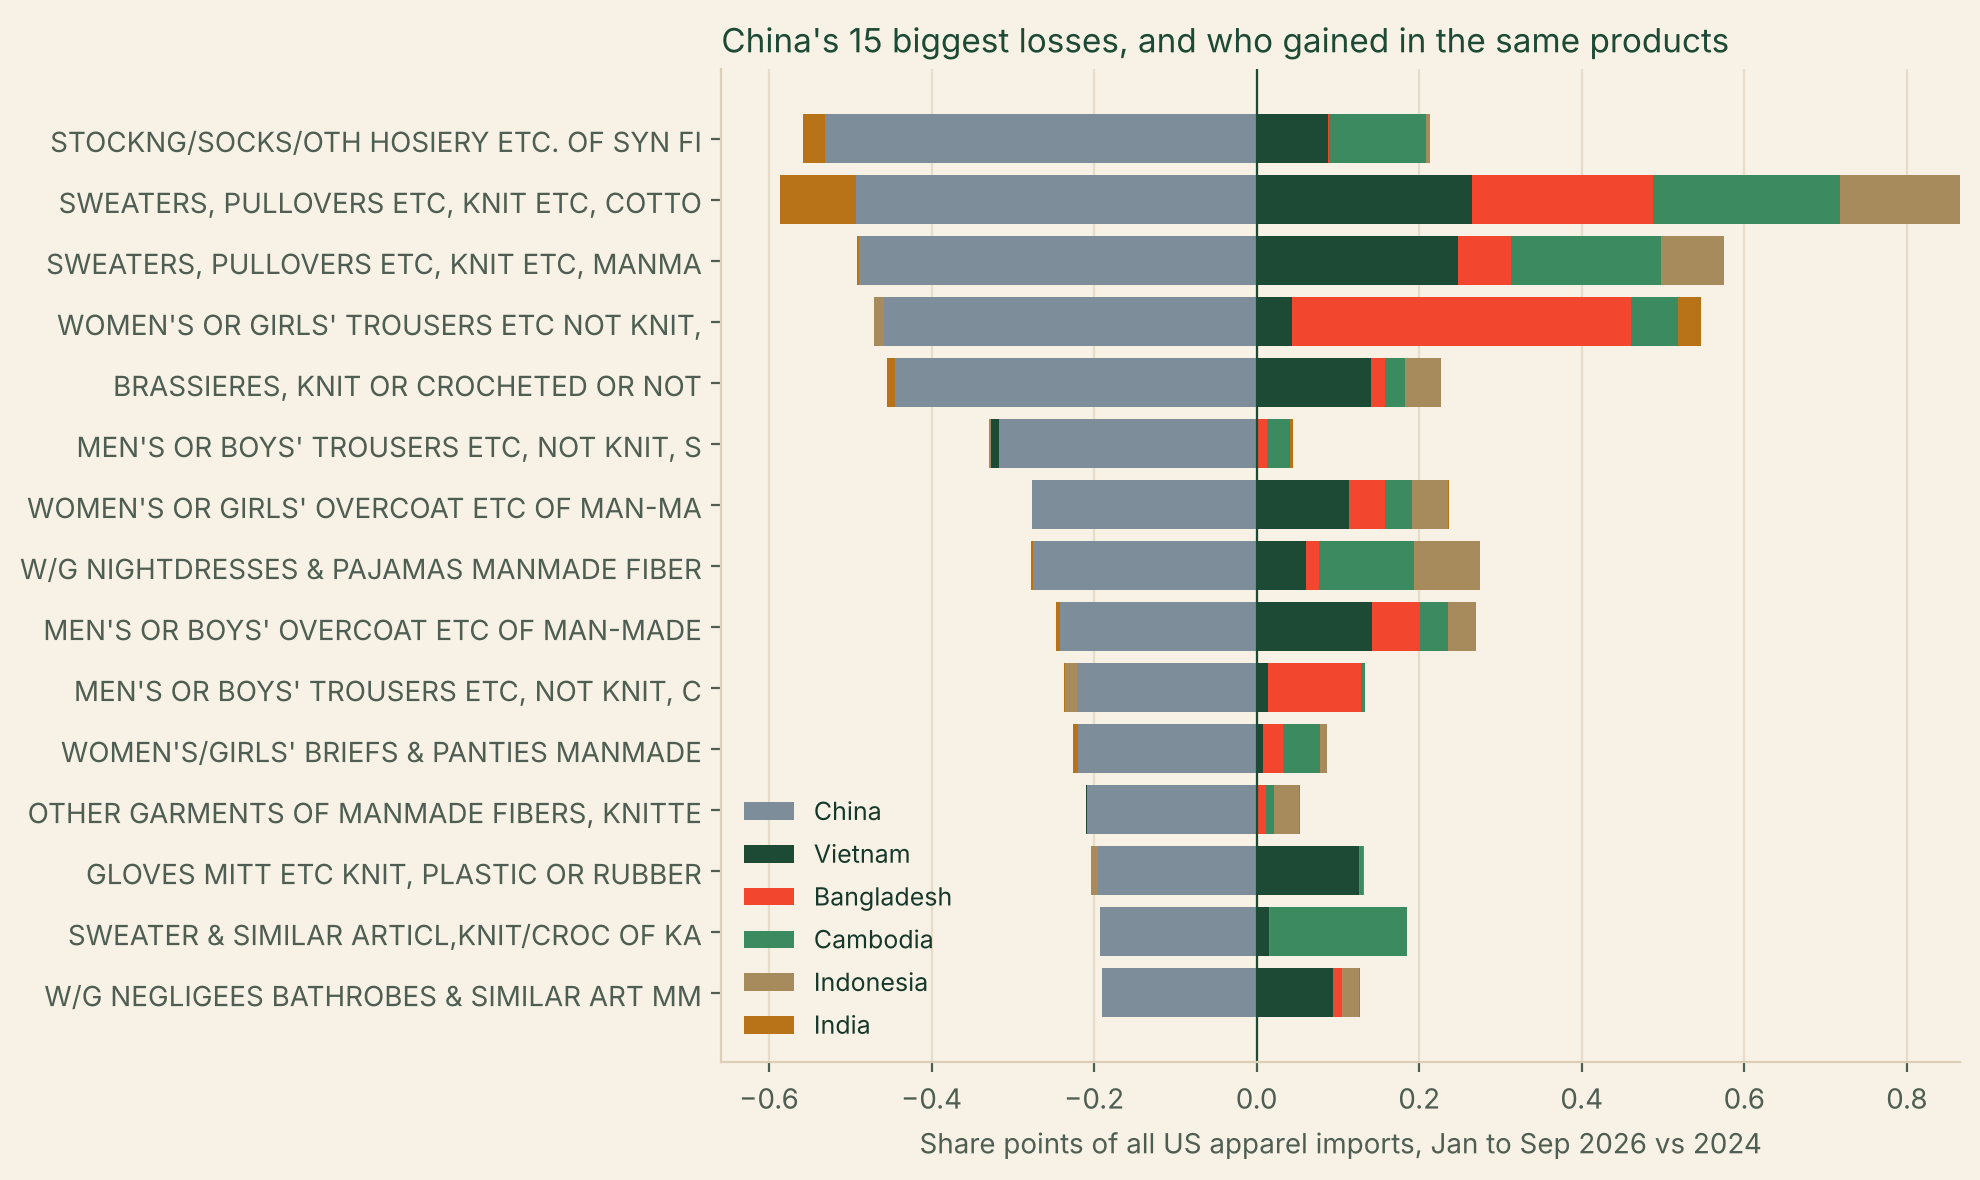

In [13]:
fig, ax = plt.subplots(figsize=(10, 6)); ax.set_axisbelow(True); ax.grid(axis="y", visible=False)
g = gain.set_index(gain["product"].str.slice(0, 40).str.strip())[["china", "vietnam", "bangladesh", "cambodia", "indonesia", "india"]]
left_neg = pd.Series(0.0, index=g.index); left_pos = pd.Series(0.0, index=g.index)
for c in g.columns:
    v = g[c]; neg = v.clip(upper=0); pos = v.clip(lower=0)
    ax.barh(g.index, neg, left=left_neg, color=COLORS[c], label=c.title()); left_neg += neg
    ax.barh(g.index, pos, left=left_pos, color=COLORS[c]); left_pos += pos
ax.invert_yaxis(); ax.axvline(0, color=GREEN, lw=0.8)
ax.set_xlabel("Share points of all US apparel imports, Jan to Sep 2026 vs 2024")
ax.set_title("China's 15 biggest losses, and who gained in the same products", loc="left", fontsize=12, color=GREEN)
ax.legend(frameon=False, fontsize=9, loc="lower left"); plt.tight_layout(); plt.show()

In [14]:
# Bangladesh: which products drove its gain?
bd = contrib[contrib.country == "bangladesh"].sort_values("pts_change", ascending=False)
bd = bd.assign(product=desc.loc[bd.hs6].str.slice(0, 50).values)
pd.concat([bd.head(10), bd.tail(5)])[["hs6", "product", 2024, 2026, "pts_change"]]

y,hs6,product,2024,2026,pts_change
141,620462,"WOMEN'S OR GIRLS' TROUSERS ETC NOT KNIT, COTTON",0.92,1.34,0.42
67,611020,"SWEATERS, PULLOVERS ETC, KNIT ETC, COTTON",0.58,0.81,0.22
119,620342,"MEN'S OR BOYS' TROUSERS ETC, NOT KNIT, COTTON",1.82,1.93,0.11
68,611030,"SWEATERS, PULLOVERS ETC, KNIT ETC, MANMADE FIBERS",0.18,0.24,0.06
70,611120,"BABIES' GARMENTS & CLTHNG ACCESS OF COTTON, KNIT",0.16,0.22,0.06
104,620140,MEN'S OR BOYS' OVERCOAT ETC OF MAN-MADE FIBERS,0.18,0.24,0.06
108,620240,WOMEN'S OR GIRLS' OVERCOAT ETC OF MAN-MADE FIBERS,0.12,0.16,0.04
149,620630,"W/G BLOUSES SHIRTS & SHIRT BLOUSES COTTON,NOT ...",0.10,0.13,0.04
132,620442,"WOMEN'S OR GIRLS' DRESSES OF COTTON, NOT KNITTED",0.06,0.09,0.03
40,610610,"WOMEN'S OR GIRLS' BLOUSES AND SHIRTS COTTON, KNIT",0.06,0.09,0.03


## 4. Bangladesh's tariff, month by month, against the dated actions

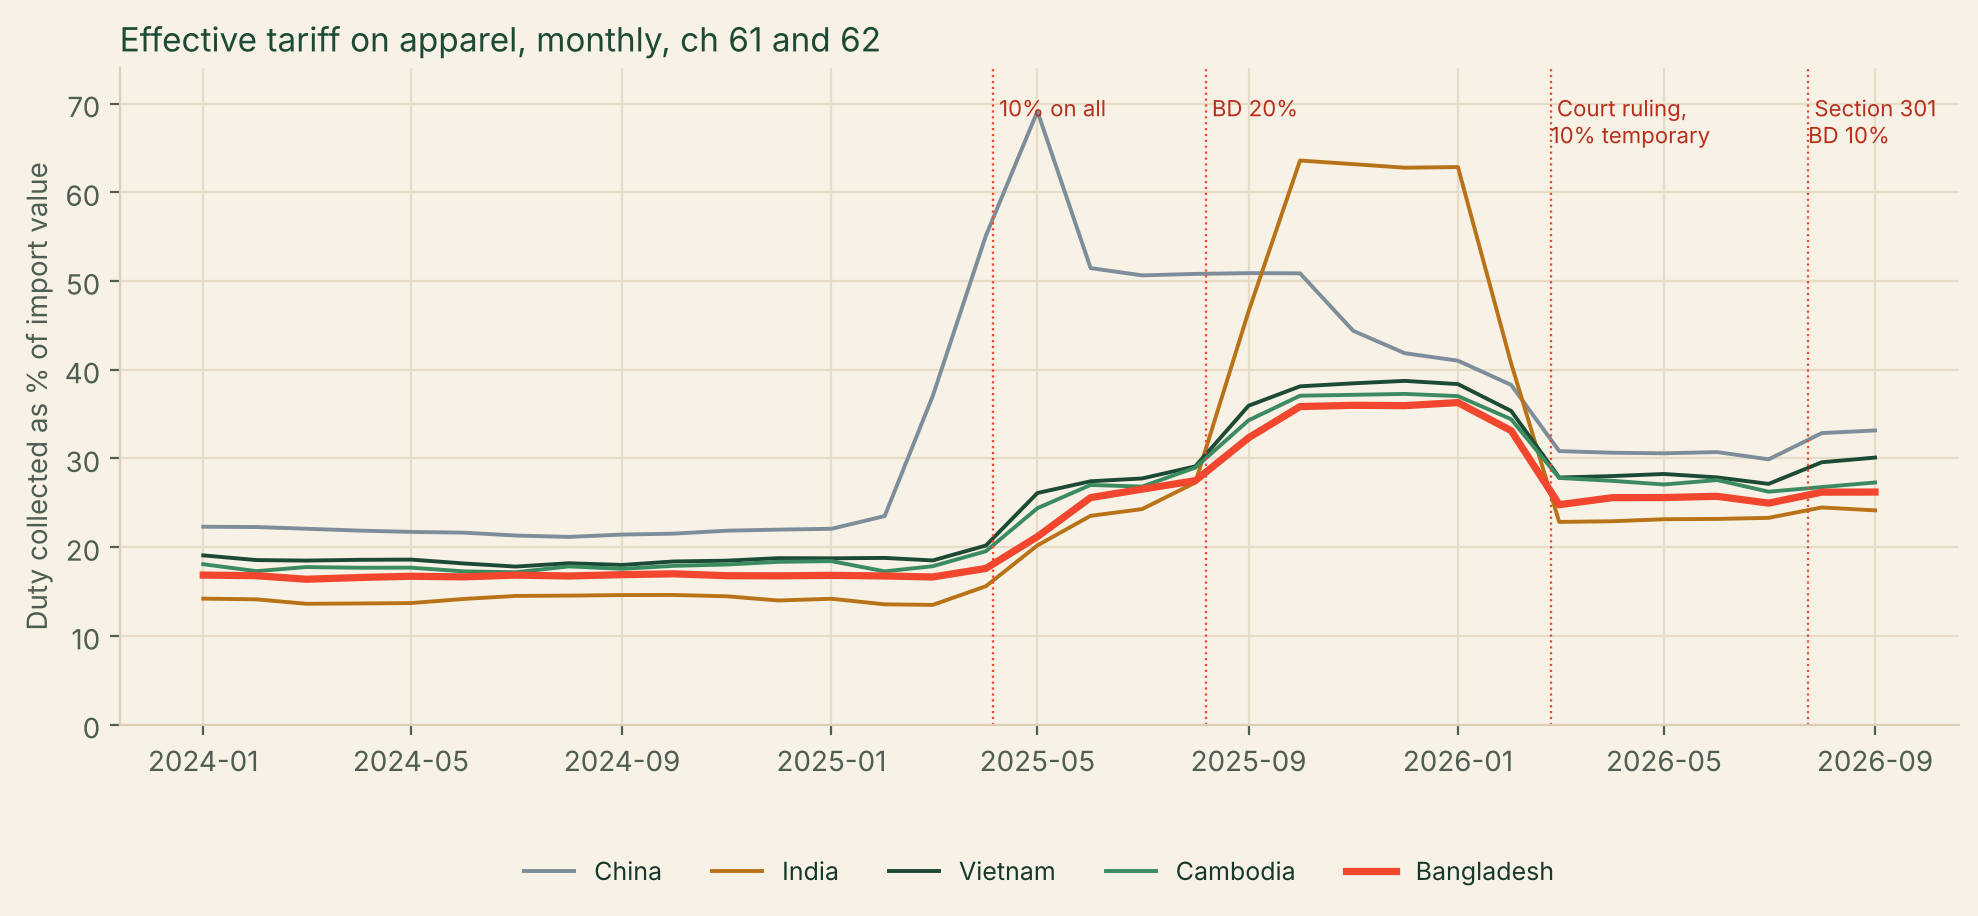

In [15]:
t = con.sql("""
select month, country, sum(duty)/sum(con_value)*100 as tariff_pct
from silver.imports where chapter in ('61','62') and country in ('bangladesh','vietnam','china','india','cambodia')
group by all order by month
""").df()
t["month"] = pd.to_datetime(t["month"])
fig, ax = plt.subplots(figsize=(10, 4.8))
for ctry in ["china", "india", "vietnam", "cambodia", "bangladesh"]:
    d = t[(t.country == ctry) & (t.month >= "2024-01-01")]
    ax.plot(d.month, d.tariff_pct, color=COLORS[ctry], lw=2.6 if ctry == "bangladesh" else 1.4, label=ctry.title())
marks = [("2025-04-05", "10% on all"), ("2025-08-07", "BD 20%"), ("2026-02-24", "Court ruling,\n10% temporary"),
         ("2026-07-24", "Section 301\nBD 10%")]
for d, lab in marks:
    ax.axvline(pd.Timestamp(d), color=TOMATO, lw=0.8, ls=":")
    ax.text(pd.Timestamp(d), 71, " " + lab, fontsize=8, color="#B8301C", va="top")
ax.set_ylim(0, 74); ax.set_ylabel("Duty collected as % of import value")
ax.set_title("Effective tariff on apparel, monthly, ch 61 and 62", loc="left", fontsize=12, color=GREEN)
ax.legend(ncol=5, frameon=False, fontsize=9, loc="lower center", bbox_to_anchor=(0.5, -0.28)); plt.tight_layout(); plt.show()

In [16]:
bdt = t[t.country == "bangladesh"].set_index("month")["tariff_pct"]
bdt["2025-01-01":].round(1).to_frame().T

month,2025-01-01,2025-02-01,2025-03-01,2025-04-01,2025-05-01,2025-06-01,2025-07-01,2025-08-01,2025-09-01,2025-10-01,...,2025-12-01,2026-01-01,2026-02-01,2026-03-01,2026-04-01,2026-05-01,2026-06-01,2026-07-01,2026-08-01,2026-09-01
tariff_pct,16.80,16.80,16.60,17.60,21.20,25.60,26.50,27.50,32.30,35.90,...,36.00,36.30,33.10,24.80,25.60,25.60,25.70,25.00,26.20,26.20


In [17]:
events[["date", "country", "measure", "rate_added"]]

,date,country,measure,rate_added
0,2025-02-04,China,IEEPA fentanyl tariff,10%
1,2025-03-04,China,IEEPA fentanyl tariff raised,20%
2,2025-04-05,All,IEEPA baseline reciprocal tariff,10%
3,2025-04-09,China,IEEPA reciprocal raised,125% (145% total with fentanyl)
4,2025-05-14,China,IEEPA cut for 90 days,30% total
5,2025-08-07,Bangladesh,IEEPA country reciprocal rate,20%
6,2025-08-07,Vietnam,IEEPA country reciprocal rate,20%
7,2025-08-07,Sri Lanka,IEEPA country reciprocal rate,20%
8,2025-08-07,Cambodia,IEEPA country reciprocal rate,19%
9,2025-08-07,Indonesia,IEEPA country reciprocal rate,19%


## Notes for the next notebook

* Shares above are January to September only. Full years come once October to December 2026 data is out.
* The monthly tariff rate counts duty when goods enter, so a new rate shows up gradually as goods already in transit clear customs.
* India's rate fell in February 2026, before the court ruling. The events list doesn't explain that yet; it needs a sourced date.
* Next: effective tariff by product and country, how much of each country's exports face the highest rates, and seasonality.